# Exercise 4.3.38 (Inpainting)

Let us consider inpainting. That is, for a vector $x_* \in \mathbb R^{N}$, we measure only entries $x_j$ for $j$ in some index set $\mathcal J \subseteq \{1, \ldots, N\}$.
This leads to the linear inverse problem $y = D x_*$, where $D$ is diagonal with elements 
$$
d_{j} = \begin{cases}
    1, & j \in \mathcal J, \\
    0, & \text{otherwise}.
\end{cases}
$$
For each pixel $j = 1,\ldots, N$, we include $j$ in $\mathcal J$ with probability $0.3$. 
As ground truth $x_*$, we use the cameraman image, available in the Python package **skimage** as **data.camera()**.
	
(i) Argue why the Tikhonov and LASSO regularization are bad choices for this problem?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

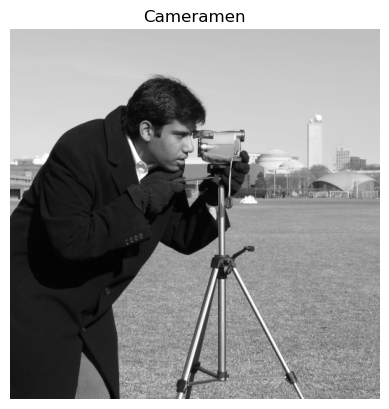

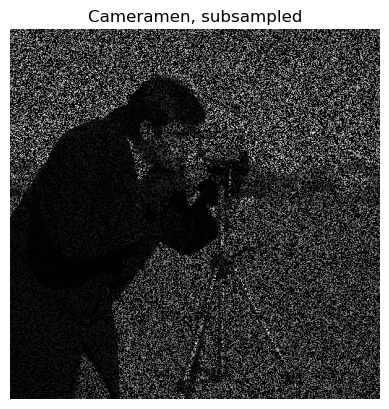

In [2]:
from skimage import data

img = data.camera()

plt.imshow(img, cmap = 'grey')
plt.title('Cameramen')
plt.axis('off')
plt.show()

mask = np.random.binomial(1, 0.3, img.shape)
meas = mask*img

plt.imshow(meas, cmap = 'grey')
plt.title('Cameramen, subsampled')
plt.axis('off')
plt.show()

(ii) Show that the discrete derivative $(\nabla x)_j = x_{j+1} - x_{j}$ from Example 4.2.9 can be implemented as convolution $\nabla x = x *_N k $ with kernel $k = e_{-1} - e_0$. See also Exercise 1.3.8. Use this observation to implement the directional derivatives
$$
(\nabla_1 \, x)_{k,j} = x_{k+1,j} - x_{k,j} 
\quad \text{and} \quad 
(\nabla_2 \, x)_{k,j} = x_{k,j+1} - x_{k,j}
$$
and their adjoints with the function **convolve(img,k, mode = 'constant')** from the Python package **ndimage**.
We use **constant** padding to account for the nonperiodic nature of $x_*$.
Test your implementation by checking that 
$$
\langle \nabla_\ell \, u, v \rangle = \langle u, \nabla_\ell^T \, v \rangle, \quad \ell = 1,2
$$
for random $u$ and $v$.  

-2.5579538487363607e-13
1.7053025658242404e-13


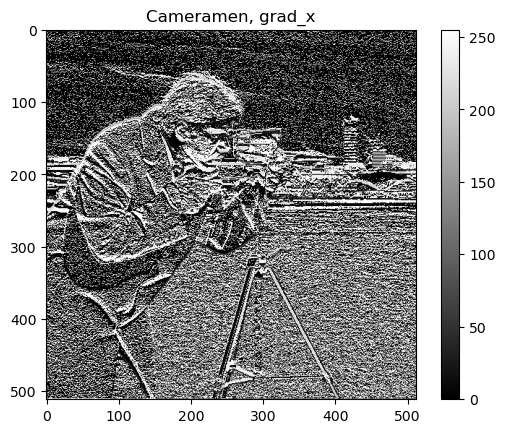

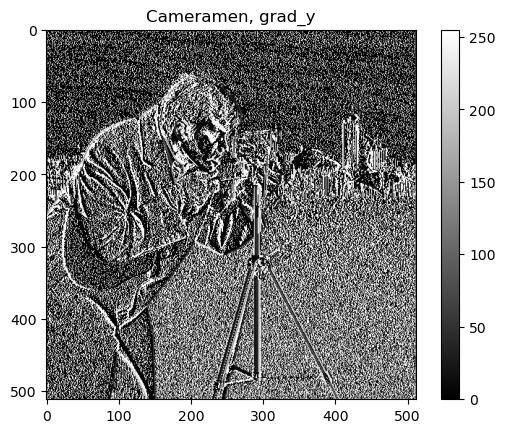

In [3]:
from scipy import ndimage

ky = np.array([ [0,0,0], [1,-1,0], [0,0,0] ])
ky_adj = np.array([ [0,0,0], [0,-1,1], [0,0,0] ])

# Sobel filter
# ky = np.array([ [1,0,-1], [2,0,-2], [1,0,-1] ])

grad_y = lambda img: ndimage.convolve(img,ky, mode = 'constant')
grad_y_adj = lambda img: ndimage.convolve(img,ky_adj, mode = 'constant')

grad_x = lambda img: ndimage.convolve(img,ky.T, mode = 'constant')
grad_x_adj = lambda img: ndimage.convolve(img,ky_adj.T, mode = 'constant')

t1 = np.random.randn(img.shape[0],img.shape[1])
t2 = np.random.randn(img.shape[0],img.shape[1])

print(np.sum(grad_x(t1) * t2) - np.sum(t1 * grad_x_adj(t2)))
print(np.sum(grad_y(t1) * t2) - np.sum(t1 * grad_y_adj(t2)))

plt.imshow(np.abs(grad_x(img)), cmap = 'grey')
plt.title('Cameramen, grad_x')
plt.colorbar()
plt.show()

plt.imshow(np.abs(grad_y(img)), cmap = 'grey')
plt.title('Cameramen, grad_y')
plt.colorbar()
plt.show()

(iii) Implement accelerated gradient descent (Algorithm 2) for the variational reconstruction objective with the smoothness prior from Example 4.2.9, namely
$$
J_\alpha(x) = \|Dx - y\|^2_2 + \alpha (\| \nabla_1 x\|^2_2 + \| \nabla_2 x \|^2_2).
$$
Visualize the reconstruction for $\alpha = 0.1$.  

In [4]:
def fast_FBS(x0, nu, grad, prox, loss, num_iter, it_thr = 0, xt = None):
    x = x0
    func_val = np.zeros((num_iter + 1))
    func_val[0] = loss(x0) 
    z = x0
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

    for k in range(num_iter):
        x_old = x
        theta = 2.0/(2 + k)
        u = (1 - theta)*x + theta*z
        x = prox(u - nu* grad(u), nu)
        z = x_old + (x - x_old) / theta
        
        func_val[k+1] = loss(x)
        if xt is not None:
            error[k+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)
        
        if it_thr > 0 and np.linalg.norm(x - x_old) < it_thr:
            break
                
    if xt is not None:
        return x, func_val, error
    else:
        return x, func_val

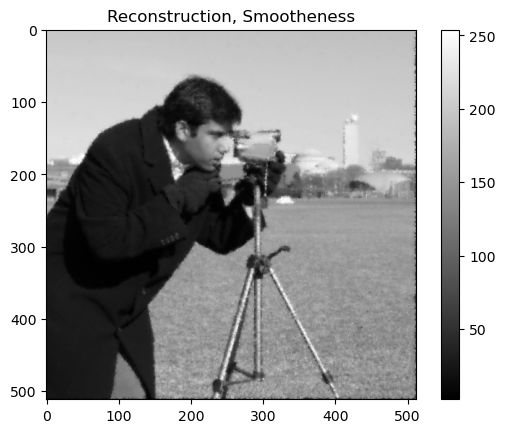

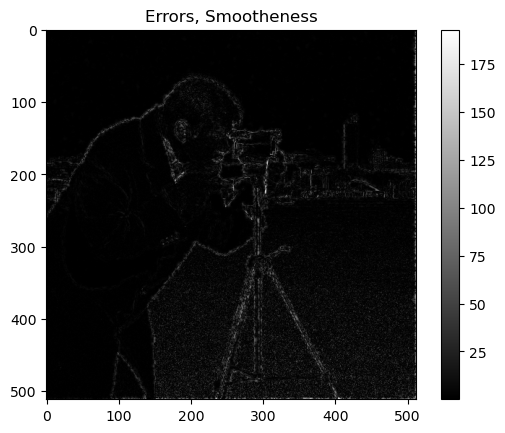

In [5]:
conv_ker = np.zeros((img.shape[0]))
conv_ker[1] = 1
conv_ker[0] = -1
spec = np.max(np.abs(np.fft.fft(conv_ker)))

num_iter = 100

alpha = 0.1
# Smoothness

grad = lambda img: mask * ( mask * img - meas) + alpha *(grad_x_adj(grad_x(img)) + grad_y_adj(grad_y(img)))
loss = lambda img: 0.5*np.linalg.norm(mask * img - meas )**2 + 0.5*alpha * (np.linalg.norm(grad_x(img))**2 + np.linalg.norm(grad_y(img))**2)
prox = lambda img,nu: img
nu = 1.0 / (1  + 2*alpha* spec**2)

x1, m_errors, errors = fast_FBS(meas, nu, grad, prox, loss,num_iter, 1e-8, img)

plt.imshow(x1, cmap = 'grey')
plt.title('Reconstruction, Smootheness')
plt.colorbar()
plt.show()

plt.imshow(np.abs(x1 - img), cmap = 'grey')
plt.title('Errors, Smootheness')
plt.colorbar()
plt.show()

(iv) Now, we want to use the TV regularization from Example 4.2.11, namely
$$
J_\alpha(x) = \|Dx - y\|^2_2 + \alpha (\| \nabla_1 x\|_1 + \| \nabla_2 x \|_1). \qquad (4.123)
$$
Based on Example 4.3.35 and Remark 4.3.26, implement the ADMM with $\gamma = 1$ to minimize (4.123) with $\alpha = 1$.
For the least squares sub-iteration, use the conjugate gradient method (or your implementation of gradient descent) with $10$ iterations and initialization $x_t$ from the previous ADMM iteration. 
Why are 10 iterations sufficient?

In [6]:
def ADMM_TV(x0, alpha, gamma, mask, meas, num_iter, num_subit, verbose = False,xt = None):
    z1 = grad_x(x0)
    z2 = grad_y(x0)
    b1 = np.zeros_like(z1)
    b2 = np.zeros_like(z2)
    x = x0
    soft_tr = lambda x,nu: np.sign(x)*np.maximum(np.abs(x) - nu*alpha, 0)
    loss_ADMM = lambda x: 0.5*np.linalg.norm(mask * x - meas )**2 + alpha * (np.sum(np.abs(grad_x(x))) + np.sum(np.abs(grad_y(x))))
    # baseline = loss_ADMM(np.zeros_like(x0))

    f_value = np.zeros((num_iter + 1))
    f_value[0] = loss_ADMM(x0)

    constr_er = np.zeros((num_iter + 1))
    constr_er[0] = np.linalg.norm(grad_x(x) - z1)**2 + np.linalg.norm(grad_y(x) - z2)**2
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)
    
    for ik in range(num_iter):
        
        # update x
        grad = lambda img: mask * ( mask * img - meas) + 0.5*gamma *(grad_x_adj(grad_x(img) - (z1 - b1)) + grad_y_adj(grad_y(img) - (z2 - b2)))
        loss = lambda img: 0.5*np.linalg.norm(mask * img - meas )**2 + 0.5*gamma * (np.linalg.norm(grad_x(img) - (z1 - b1))**2 + np.linalg.norm(grad_y(img) - (z2 - b2))**2)
        prox_id = lambda img,nu: img
        nu = 1.0 / (1  + gamma * spec**2)
        x, er = fast_FBS(x, nu, grad, prox_id, loss,num_subit, 1e-8)

        f_value[ik+1] = loss_ADMM(x)
        
        if xt is not None:
            error[ik+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

        # update z
        z1 = soft_tr(b1 + grad_x(x),alpha / gamma)
        z2 = soft_tr(b2 + grad_y(x),alpha / gamma)
        
        constr_er[ik+1] = np.linalg.norm(grad_x(x) - z1)**2 + np.linalg.norm(grad_y(x) - z2)**2

        if verbose:
            if xt is not None:
                print(f"Iteration: {ik} F: {f_value[ik+1]:.1f} Const. error: {constr_er[ik+1]:.1f} Rel. Error: {error[ik+1]:.5f}")
            else:
                print(f"Iteration: {ik} F: {f_value[ik+1]:.1f} Const. error: {constr_er[ik+1]:.1f}")

        # update b
        b1 = b1 + grad_x(x) - z1
        b2 = b2 + grad_y(x) - z2

    if xt is not None:
        return x, constr_er, error
    else:
        return x, constr_er,

In [7]:
num_iter = 500
num_subit = 10

img_rec, constr_er, errors = ADMM_TV(x0 = meas, 
                                               alpha = 1e0,
                                               gamma= 1e0, 
                                               mask = mask, 
                                               meas = meas, 
                                               num_iter = num_iter, 
                                               num_subit = num_subit, 
                                               verbose = True,
                                               xt = img)

Iteration: 0 F: 28696051.0 Const. error: 255492.0 Rel. Error: 0.83681
Iteration: 1 F: 28330950.7 Const. error: 7911.7 Rel. Error: 0.83105
Iteration: 2 F: 28139668.6 Const. error: 3002.0 Rel. Error: 0.82682
Iteration: 3 F: 27958632.9 Const. error: 2017.2 Rel. Error: 0.82281
Iteration: 4 F: 27779731.0 Const. error: 1682.0 Rel. Error: 0.81884
Iteration: 5 F: 27604166.1 Const. error: 2051.3 Rel. Error: 0.81491
Iteration: 6 F: 27430065.2 Const. error: 1877.6 Rel. Error: 0.81099
Iteration: 7 F: 27257352.8 Const. error: 1582.9 Rel. Error: 0.80709
Iteration: 8 F: 27086109.9 Const. error: 1405.2 Rel. Error: 0.80320
Iteration: 9 F: 26916114.9 Const. error: 1278.4 Rel. Error: 0.79933
Iteration: 10 F: 26747145.3 Const. error: 1170.4 Rel. Error: 0.79546
Iteration: 11 F: 26579154.3 Const. error: 1076.2 Rel. Error: 0.79161
Iteration: 12 F: 26411977.9 Const. error: 983.1 Rel. Error: 0.78777
Iteration: 13 F: 26245541.3 Const. error: 887.0 Rel. Error: 0.78393
Iteration: 14 F: 26079706.9 Const. error: 78

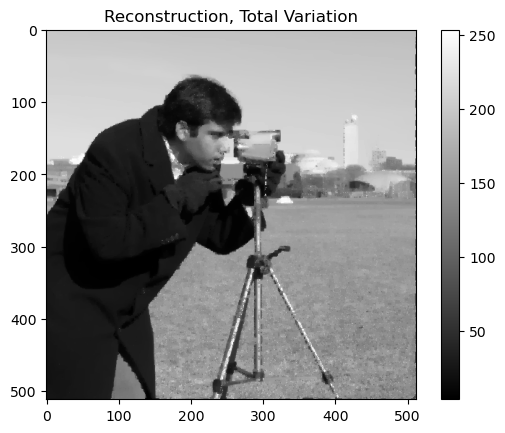

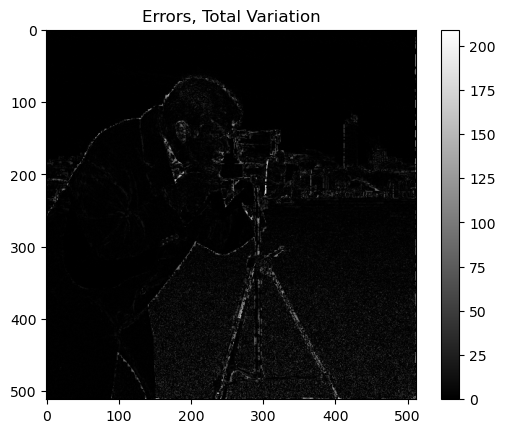

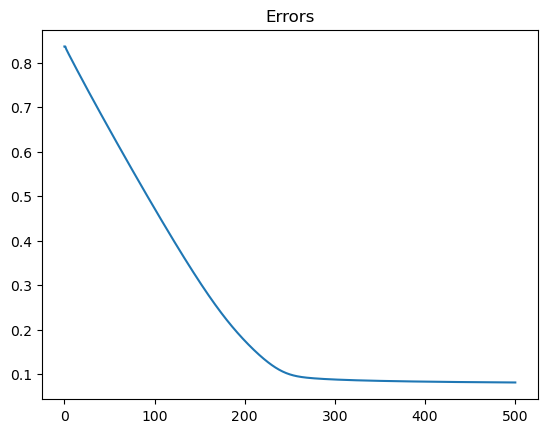

In [8]:
plt.imshow(img_rec, cmap = 'grey')
plt.title('Reconstruction, Total Variation')
plt.colorbar()
plt.show()

plt.imshow(np.abs(img_rec - img), cmap = 'grey')
plt.title('Errors, Total Variation')
plt.colorbar()
plt.show()

plt.plot(errors)
plt.title('Errors')
plt.show()

(v) Plot the absolute errors $| D(x - x_*)|$. For inpainting, we want to enforce that the error on the measured pixels is zero. This is done via the functional
$$
J(x) = \iota_{ \{z \colon Dz = y\}}(x) + \| \nabla_1 x\|_1 + \| \nabla_2 x \|_1, \qquad (4.124)
$$
where 
$$
    \iota_{\mathcal S}(x) = \begin{cases}
    0, & x \in \mathcal S,\\
    \infty, & x \notin \mathcal S.
\end{cases}
$$
Implement ADMM with $\gamma = 0.01$ for minimizing (4.124) and perform the reconstruction.
Plot the absolute errors $| D(x - x_*) |$ again and explain the difference.



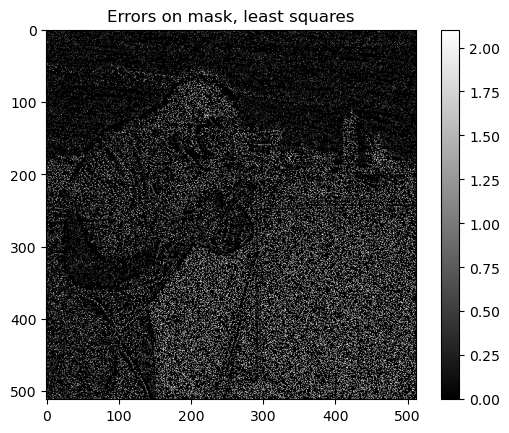

In [9]:
plt.imshow(np.abs(img_rec - img)*mask, cmap = 'grey')
plt.title('Errors on mask, least squares')
plt.colorbar()
plt.show()

In [10]:
def ADMM_inpainting_TV(x0, gamma, mask, meas, num_iter, num_subit, verbose = False,xt = None):
    z1 = grad_x(x0)
    z2 = grad_y(x0)
    b0 = mask * x0 - meas
    b1 = np.zeros_like(z1)
    b2 = np.zeros_like(z2)
    x = x0
    prox = lambda x,nu: np.sign(x)*np.maximum(np.abs(x) - nu*alpha, 0)
    
    constr_er = np.zeros((num_iter + 1))
    constr_er[0] = np.linalg.norm(mask*x - meas)**2 + np.linalg.norm(grad_x(x) - z1)**2 + np.linalg.norm(grad_y(x) - z2)**2
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)
    
    for ik in range(num_iter):
        
        # update x
        grad = lambda img: 0.5*gamma *( mask * ( mask * img - (meas - b0)) + grad_x_adj(grad_x(img) - (z1 - b1)) + grad_y_adj(grad_y(img) - (z2 - b2)))
        loss = lambda img: 0.5*np.linalg.norm(mask * img - (meas + b0) )**2 + 0.5*gamma * (np.linalg.norm(grad_x(img) - (z1 - b1))**2 + np.linalg.norm(grad_y(img) - (z2 - b2))**2)
        prox_id = lambda img,nu: img
        nu = 1.0 / (gamma * (0.5  +  spec**2))
        x, er = fast_FBS(x, nu, grad, prox_id, loss,num_subit, 1e-8)
        
        if xt is not None:
            # print(xt.shape)
            # print(x.shape)
            # print(np.linalg.norm(x-xt))
            error[ik+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

        # update z
        z1 = prox(b1 + grad_x(x),1.0 / gamma)
        z2 = prox(b2 + grad_y(x),1.0 / gamma)
        
        constr_er[ik+1] = np.linalg.norm(mask*x - meas)**2 + np.linalg.norm(grad_x(x) - z1)**2 + np.linalg.norm(grad_y(x) - z2)**2

        if verbose:
            if xt is not None:
                print(f"Iteration: {ik} Const. error: {constr_er[ik+1]:.1f} Rel. Error: {error[ik+1]:.5f}")
            else:
                print(f"Iteration: {ik} Const. error: {constr_er[ik+1]:.1f}")
                    
        # update b
        b0 = b0 + mask * x - meas
        b1 = b1 + grad_x(x) - z1
        b2 = b2 + grad_y(x) - z2

    if xt is not None:
        return x, constr_er, error
    else:
        return x, constr_er,

In [11]:
num_iter = 500
num_subit = 10

img_rec_in, constr_er, errors = ADMM_inpainting_TV(x0 = meas, 
                                               gamma= 1e-2, 
                                               mask = mask, 
                                               meas = meas, 
                                               num_iter = num_iter, 
                                               num_subit = num_subit, 
                                               verbose = True,
                                               xt = img)

Iteration: 0 Const. error: 22633284.0 Rel. Error: 0.83681
Iteration: 1 Const. error: 4886448.7 Rel. Error: 0.78854
Iteration: 2 Const. error: 2055846.5 Rel. Error: 0.73849
Iteration: 3 Const. error: 1680588.1 Rel. Error: 0.68946
Iteration: 4 Const. error: 1608181.7 Rel. Error: 0.64630
Iteration: 5 Const. error: 1311514.1 Rel. Error: 0.60855
Iteration: 6 Const. error: 864707.4 Rel. Error: 0.57386
Iteration: 7 Const. error: 565365.9 Rel. Error: 0.54017
Iteration: 8 Const. error: 483592.7 Rel. Error: 0.50628
Iteration: 9 Const. error: 468933.1 Rel. Error: 0.47187
Iteration: 10 Const. error: 427171.5 Rel. Error: 0.43721
Iteration: 11 Const. error: 370913.5 Rel. Error: 0.40280
Iteration: 12 Const. error: 327614.6 Rel. Error: 0.36907
Iteration: 13 Const. error: 315748.1 Rel. Error: 0.33628
Iteration: 14 Const. error: 349232.9 Rel. Error: 0.30459
Iteration: 15 Const. error: 457853.5 Rel. Error: 0.27417
Iteration: 16 Const. error: 637304.5 Rel. Error: 0.24529
Iteration: 17 Const. error: 897414

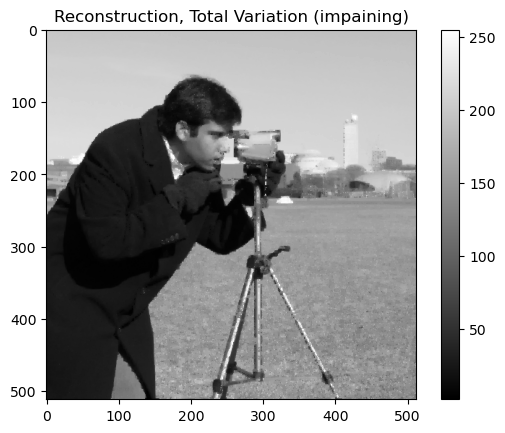

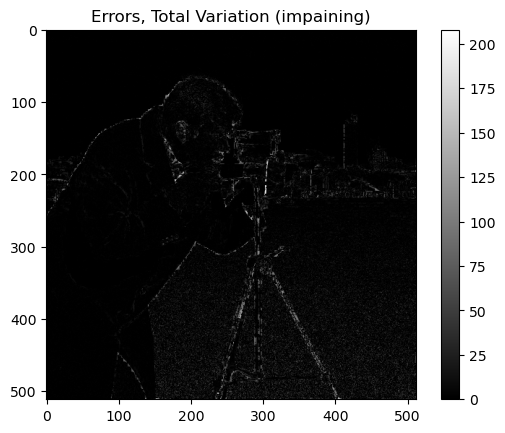

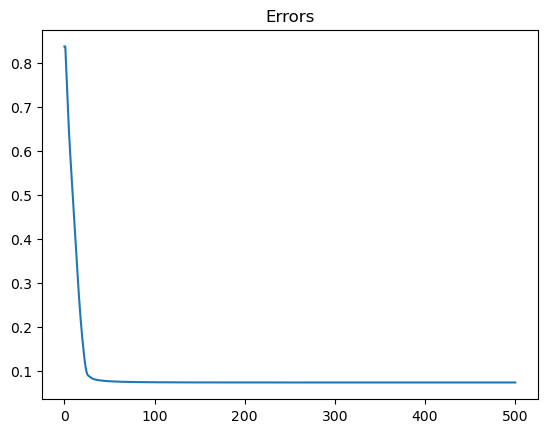

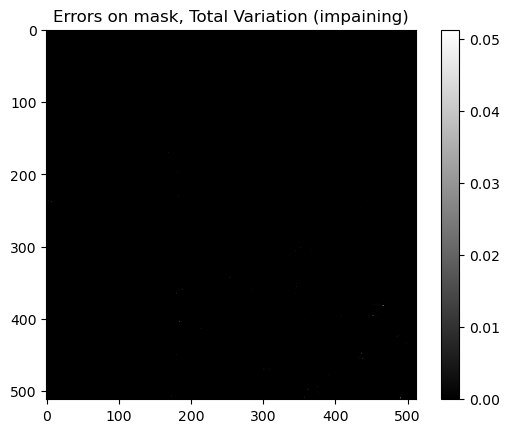

In [12]:
plt.imshow(img_rec_in, cmap = 'grey')
plt.title('Reconstruction, Total Variation (impaining)')
plt.colorbar()
plt.show()

plt.imshow(np.abs(img_rec_in - img), cmap = 'grey')
plt.title('Errors, Total Variation (impaining)')
plt.colorbar()
plt.show()

plt.plot(errors)
plt.title('Errors')
plt.show()

plt.imshow(np.abs(img_rec_in - img)*mask, cmap = 'grey')
plt.title('Errors on mask, Total Variation (impaining)')
plt.colorbar()
plt.show()

(vi) Now, we change the sampling of $\mathcal J$.
Instead of random  pixels, we exclude a $50 \times 50$ box that contains the cameraman's face.
Try to reconstruct it with the algorithms from above and explain the outcome.

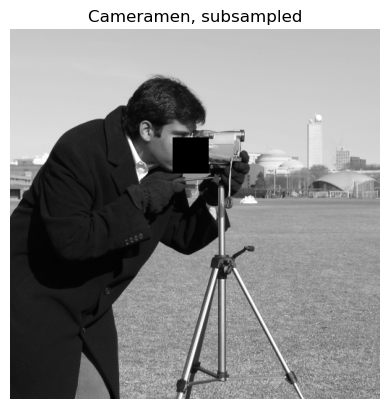

In [13]:
mask = np.ones_like(img)
mask[150:200,225:275] = 0

meas = mask * img

plt.imshow(meas, cmap = 'grey')
plt.title('Cameramen, subsampled')
plt.axis('off')
plt.show()

In [14]:
num_iter = 100
alpha = 0.1

# Smoothness

grad = lambda img: mask * ( mask * img - meas) + alpha *(grad_x_adj(grad_x(img)) + grad_y_adj(grad_y(img)))
loss = lambda img: 0.5*np.linalg.norm(mask * img - meas )**2 + 0.5*alpha * (np.linalg.norm(grad_x(img))**2 + np.linalg.norm(grad_y(img))**2)
prox = lambda img,nu: img
nu = 1.0 / (1  + 2*alpha* spec**2)

x1, m_errors, errors = fast_FBS(meas, nu, grad, prox, loss,num_iter, 1e-8, img)

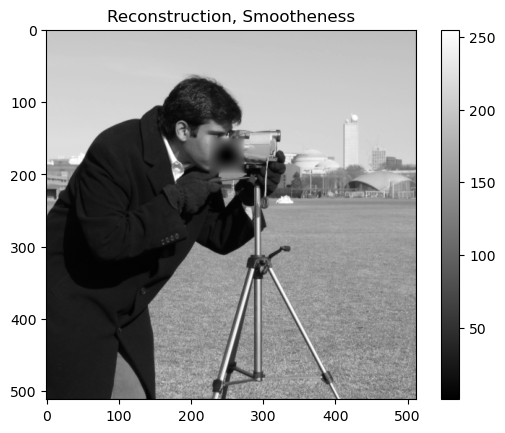

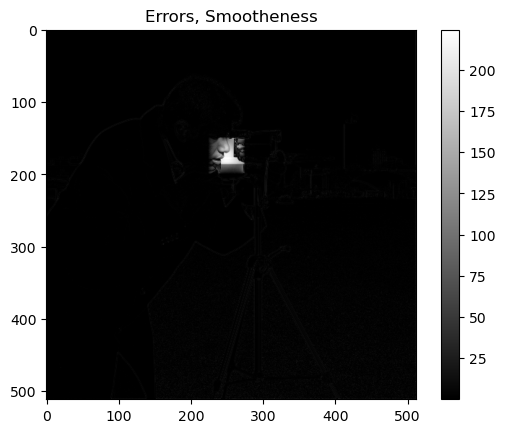

In [15]:
plt.imshow(x1, cmap = 'grey')
plt.title('Reconstruction, Smootheness')
plt.colorbar()
plt.show()

plt.imshow(np.abs(x1 - img), cmap = 'grey')
plt.title('Errors, Smootheness')
plt.colorbar()
plt.show()

In [16]:
# ADMM TV
num_iter = 500
num_subit = 10

img_rec_face, constr_er_face, errors_face = ADMM_TV(x0 = meas, 
                                       alpha = 1e+0,
                                       gamma= 1e0, 
                                       mask = mask, 
                                       meas = meas, 
                                       num_iter = num_iter, 
                                       num_subit = num_subit, 
                                       verbose = True,
                                       xt = img)

Iteration: 0 F: 331367048.9 Const. error: 516422.1 Rel. Error: 0.34072
Iteration: 1 F: 127467488.4 Const. error: 123328.4 Rel. Error: 0.22067
Iteration: 2 F: 60226706.2 Const. error: 146919.9 Rel. Error: 0.16504
Iteration: 3 F: 30929699.4 Const. error: 143886.2 Rel. Error: 0.13497
Iteration: 4 F: 17055051.2 Const. error: 99068.3 Rel. Error: 0.11882
Iteration: 5 F: 10206406.3 Const. error: 89804.1 Rel. Error: 0.11034
Iteration: 6 F: 6732074.0 Const. error: 77738.4 Rel. Error: 0.10597
Iteration: 7 F: 4933000.4 Const. error: 64940.3 Rel. Error: 0.10372
Iteration: 8 F: 3998141.2 Const. error: 56691.4 Rel. Error: 0.10256
Iteration: 9 F: 3528604.2 Const. error: 52660.0 Rel. Error: 0.10194
Iteration: 10 F: 3326990.0 Const. error: 54404.2 Rel. Error: 0.10160
Iteration: 11 F: 3259756.7 Const. error: 48480.5 Rel. Error: 0.10139
Iteration: 12 F: 3234728.2 Const. error: 29033.5 Rel. Error: 0.10124
Iteration: 13 F: 3222009.9 Const. error: 12076.9 Rel. Error: 0.10111
Iteration: 14 F: 3217213.4 Const

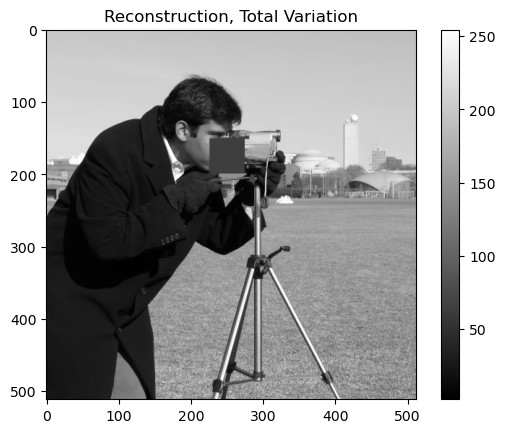

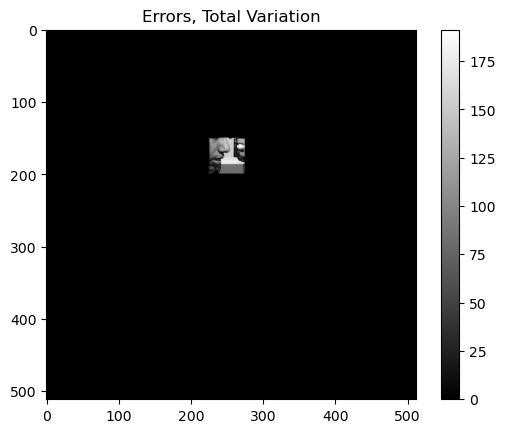

In [17]:
plt.imshow(img_rec_face, cmap = 'grey')
plt.title('Reconstruction, Total Variation')
plt.colorbar()
plt.show()

plt.imshow(np.abs(img_rec_face - img), cmap = 'grey')
plt.title('Errors, Total Variation')
plt.colorbar()
plt.show()

In [18]:
# ADMM impaining
img_rec_im_face, constr_er_im_face, errors_im_face = ADMM_inpainting_TV(x0 = meas, 
                                               gamma= 1e-2, 
                                               mask = mask, 
                                               meas = meas, 
                                               num_iter = num_iter, 
                                               num_subit = num_subit, 
                                               verbose = True,
                                               xt = img)

Iteration: 0 Const. error: 1055704547.6 Rel. Error: 0.42962
Iteration: 1 Const. error: 202284717.5 Rel. Error: 0.20426
Iteration: 2 Const. error: 109932877.1 Rel. Error: 0.14148
Iteration: 3 Const. error: 110206599.5 Rel. Error: 0.13783
Iteration: 4 Const. error: 62152139.2 Rel. Error: 0.13809
Iteration: 5 Const. error: 63070595.9 Rel. Error: 0.14142
Iteration: 6 Const. error: 51761986.7 Rel. Error: 0.13432
Iteration: 7 Const. error: 33398725.8 Rel. Error: 0.12137
Iteration: 8 Const. error: 17199355.2 Rel. Error: 0.10847
Iteration: 9 Const. error: 8150603.6 Rel. Error: 0.09994
Iteration: 10 Const. error: 5831960.7 Rel. Error: 0.09628
Iteration: 11 Const. error: 5722528.8 Rel. Error: 0.09494
Iteration: 12 Const. error: 4868220.6 Rel. Error: 0.09388
Iteration: 13 Const. error: 3506833.1 Rel. Error: 0.09250
Iteration: 14 Const. error: 2580372.8 Rel. Error: 0.09089
Iteration: 15 Const. error: 1741188.7 Rel. Error: 0.08920
Iteration: 16 Const. error: 1132799.4 Rel. Error: 0.08768
Iteration:

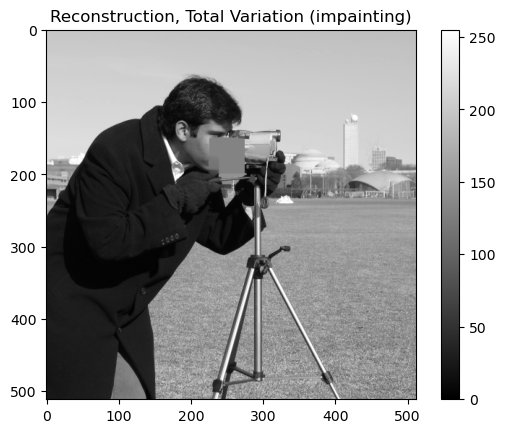

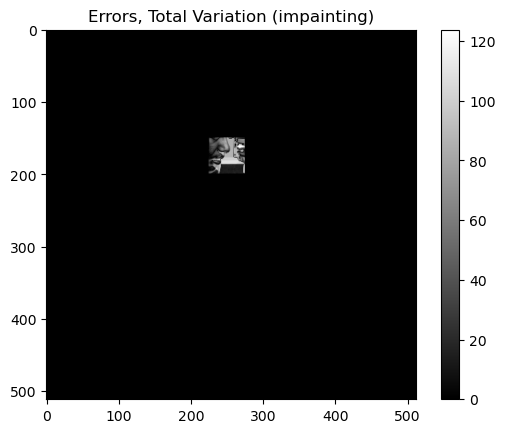

In [19]:
plt.imshow(img_rec_im_face, cmap = 'grey')
plt.title('Reconstruction, Total Variation (impainting)')
plt.colorbar()
plt.show()

plt.imshow(np.abs(img_rec_im_face - img), cmap = 'grey')
plt.title('Errors, Total Variation (impainting)')
plt.colorbar()
plt.show()